# BA305 — My Descriptive Analysis (Option B)

**What was Josh's task:** Working on how women are represented in the highest- and lowest-paid groups within UK employers. This is the structured visual analysis part of our team project, using methods from BA305 Sessions 2–3.

**My question:** *Among employers with similar median hourly gender pay gaps, how does women's underrepresentation in the top pay quartile compare with their overrepresentation in the bottom pay quartile?*

**In simpler words(For Josh at least):** Let's say that two companies could  both be report a 10% median hourly pay gap. But one company might have women be less represented in the highest-paid group, while in another, women might be more concentrated in the lowest-paid group. I want to explore on whether those different patterns show up in the data.

**Role in the project:** Our team decided to be acting as a workplace gender-equality certification organization. I hope to have charts that would help the organization figure out as to which companies need a closer look and what information to ask for. **The charts alone should not decide who gets certified, but could help shortlist.**

**Focus dataset:** UK gender pay gap filings from **2021–2022** as each year the employer's are the same and does not need all datasets. Each row is an employer filing, there was no usage of. I will look at employer size and industry to see whether the patterns change across groups.

**Disclaimer:** These filings are not meant to tell whether two employees doing the same job are paid differently or why any gap exists. these charts are not meant to be used for discrimination, but are helpful in seeing which companies we want to promote.

**AI usage:** This is my analysis notebook, **not** to be used for final report or slides. The notebook's code and learning explanations were revised with OpenAI GPT-6 assistance. While the codes were generated, they were all inspected by Josh on what code and outputs produced.

**to the team:** yes the code is Ai generated, but all of my explainations and findings will be verified by me, and I'll ensure I can explain the findsings and reasoning. As for the reason above of writing above? It's mostly for me to explain myself througout the process.


## Guidlines for Josh (yes to myself) in this notebook

For each part, I'll have to ask myself:

1. **What am I comparing?** Which employers or numbers are in the chart?
2. **Why did I choose this?** How does it help answer my question?
3. **What does it actually show?** I should use the results, not guess what they will be.
4. **Why would a reviewer care?** What should the certification organization check next?

Once the code runs, I'll write notes in my own words based on the **real outputs**. I'll also save the notebook with the charts and tables visible before submitting it.

**References:** [Session 3 visualization lab](https://github.com/elhamod/BA305_Fall_2026/blob/main/Session%2003%20-%20Data%20Visualization%20II%20-%20Building%20Charts/lab1_visualization.ipynb) · [BA305 project directives](https://github.com/elhamod/BA305_Fall_2026/blob/main/Project/PROJECT_DIRECTIVES.md) · [Our team's GitHub](https://github.com/runkael2/BA305-A6-Team-Project).


## 1. Using our team's dataset

I'm using **2021–2022** so that I'm comparing employers from the same reporting period instead of mixing years together.

**What I'll check:** How many filings are in that year, what the column names are, and what the first few rows look like.

**Why it matters:** If the wrong year or column is used, the rest of my charts won't be reliable.

**Coding note:** The team file may use `CurrentName` instead of `EmployerName`. The code can rename that **column heading inside this notebook** without changing any company names or values.

**Lecture connection:** Session 3 — `pd.read_csv`, `head()`, and looking at the data before charting it.


In [1]:
# Josh — Section 1: data loading (AI-assisted: OpenAI GPT-6, November 2026)
# Verify and disclose AI assistance under BA305 project §9.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA_URL = ("https://raw.githubusercontent.com/runkael2/"
            "BA305-A6-Team-Project/main/UK_Gender_Pay_Gap_workbook_allyears.csv")
all_filings = pd.read_csv(DATA_URL, encoding='utf-8-sig', low_memory=False)

# Team A6's file may label the company as CurrentName rather than EmployerName.
# This only renames a header inside this notebook — it does not change company values.
if 'EmployerName' not in all_filings.columns and 'CurrentName' in all_filings.columns:
    all_filings = all_filings.rename(columns={'CurrentName':'EmployerName'})

required = ['ReportingPeriod', 'EmployerId', 'EmployerName', 'EmployerSize',
            'Industry', 'DiffMedianHourlyPercent',
            'FemaleLowerQuartile', 'FemaleLowerMiddleQuartile',
            'FemaleUpperMiddleQuartile', 'FemaleTopQuartile']
missing_columns = sorted(set(required) - set(all_filings.columns))
if missing_columns:
    raise ValueError(f'Team CSV is missing expected columns: {missing_columns}')

print('Records in each reporting period:')
print(all_filings['ReportingPeriod'].value_counts(dropna=False).sort_index())
df = all_filings.loc[all_filings['ReportingPeriod'] == '2021-2022'].copy()
if df.empty:
    raise ValueError('No rows have ReportingPeriod = 2021-2022. Inspect the CSV labels.')
print('\n2021–2022 filing records:', len(df))
display(df[required].head(5))


Records in each reporting period:
ReportingPeriod
2017-2018    10230
2018-2019    10471
2019-2020     6924
2020-2021    10536
2021-2022    10425
2022-2023      125
Name: count, dtype: int64

2021–2022 filing records: 10425


,ReportingPeriod,EmployerId,EmployerName,EmployerSize,Industry,DiffMedianHourlyPercent,FemaleLowerQuartile,FemaleLowerMiddleQuartile,FemaleUpperMiddleQuartile,FemaleTopQuartile
38161,2021-2022,19070,'PRIFYSGOL ABERYSTWYTH' AND 'ABERYSTWYTH UNIVE...,1000 to 4999,Unknown,3.7,48.3,59.6,59.1,44.4
38162,2021-2022,16879,"""RED BAND"" CHEMICAL COMPANY, LIMITED",250 to 499,Wholesale & Retail Trade,-4.4,59.0,76.8,95.1,79.5
38163,2021-2022,15320,1509 GROUP,Less than 250,Education,16.0,64.0,64.0,50.0,29.0
38164,2021-2022,687,1LIFE MANAGEMENT SOLUTIONS LIMITED,Less than 250,Arts/Entertainment,-35.3,41.7,65.2,65.2,52.2
38165,2021-2022,17484,1ST HOME CARE LTD.,Less than 250,Health/SocialWork,0.0,91.0,91.0,91.0,92.0


##Check for missing or unusual data

Before I compare companies, I need to make sure the percentages make sense. For example, a quartile cannot be **120% women**, and a missing value is not the same as zero.

**What I'll check:**
- How many pay-gap and female-quartile values are missing.
- Whether any percentages are below 0 or above 100.
- Whether female and male percentages add up to about 100 when both are available.
- Whether the same employer ID appears more than once in 2021–2022.

If more than roughly **5%** of an important field is missing, I need to explain why that matters. I'm not going to fill in missing female-quartile values with made-up numbers because those values are exactly what I'm studying, plus it would be very contradicting for me to match

A repeated employer ID also needs attention. Later, I'll remove exact analytical duplicates and leave out conflicting repeated IDs from the main one-employer comparison. I'll show how many rows this affects rather than hide it.

**Limit to remember:** This is data from employers that reported, not a complete picture of every UK workplace.


In [2]:
# Josh — Section 2: data-quality audit (AI-assisted: OpenAI GPT-6, November 2026)
female_cols = ['FemaleLowerQuartile', 'FemaleLowerMiddleQuartile',
               'FemaleUpperMiddleQuartile', 'FemaleTopQuartile']
male_cols = ['MaleLowerQuartile', 'MaleLowerMiddleQuartile',
             'MaleUpperMiddleQuartile', 'MaleTopQuartile']

for column in ['DiffMedianHourlyPercent'] + female_cols + male_cols:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors='coerce')

quality = pd.DataFrame({
    'missing_n': df[['DiffMedianHourlyPercent'] + female_cols].isna().sum(),
    'missing_pct': 100 * df[['DiffMedianHourlyPercent'] + female_cols].isna().mean()
})
display(quality.round(2))
print('Fields over 5% missing:', quality.index[quality['missing_pct'] > 5].tolist())

quartiles_valid = df[female_cols].notna().all(axis=1) & df[female_cols].ge(0).all(axis=1) & df[female_cols].le(100).all(axis=1)
print('Missing/invalid female-quartile records in this year:', int((~quartiles_valid).sum()))
print('Records missing EmployerId:', int(df['EmployerId'].isna().sum()))
for f,m in zip(female_cols, male_cols):
    if m in df.columns:
        both = df[f].notna() & df[m].notna()
        mismatches = both & ((df[f] + df[m] - 100).abs() > 0.2)
        print(f'{f}: {int(mismatches.sum())} records where female + male differs from 100 by >0.2 pp')

repeated_ids = df['EmployerId'].notna() & df.duplicated('EmployerId', keep=False)
print('Repeated employer-ID rows in this year:', int(repeated_ids.sum()))
print('Different repeated employer IDs:', int(df.loc[repeated_ids, 'EmployerId'].nunique()))
if repeated_ids.any():
    display(df.loc[repeated_ids, ['EmployerId','EmployerName','EmployerSize','Industry','DiffMedianHourlyPercent'] + female_cols].head(10))
print('Interpretation to write yourself: Are missingness / duplicates large enough to affect the story?')


,missing_n,missing_pct
DiffMedianHourlyPercent,0,0.00
FemaleLowerQuartile,192,1.84
FemaleLowerMiddleQuartile,192,1.84
FemaleUpperMiddleQuartile,192,1.84
FemaleTopQuartile,192,1.84


Fields over 5% missing: []
Missing/invalid female-quartile records in this year: 192
Records missing EmployerId: 0
FemaleLowerQuartile: 0 records where female + male differs from 100 by >0.2 pp
FemaleLowerMiddleQuartile: 0 records where female + male differs from 100 by >0.2 pp
FemaleUpperMiddleQuartile: 0 records where female + male differs from 100 by >0.2 pp
FemaleTopQuartile: 0 records where female + male differs from 100 by >0.2 pp
Repeated employer-ID rows in this year: 0
Different repeated employer IDs: 0
Interpretation to write yourself: Are missingness / duplicates large enough to affect the story?


## 3. Compare companies with similar pay gaps

For now, I'm looking at employers with a reported **median hourly gender pay gap between 8% and 12%**. I picked this range because it keeps the headline gap fairly similar while giving me companies to compare. It is **my analysis choice**, not an official standard for a 'similar' gap, so if the team wants to change, we can.

I'll also keep the reporting employer-size groups starting at **250 employees** as anything lower could flucuate.

**What happens in the code:** It checks that the employer ID and quartile percentages are usable, removes exact analytical duplicates, and excludes conflicting repeated employer IDs for this comparison. It prints how many records were removed at each stage.

**What I want to know:** Do I still have enough employers after filtering? If too many get removed, I need to be cautious about what the sample represents.

The later sensitivity checks will use the same cleaning rules so the comparisons are fair.

Based on this, we have enough data to work with for the range specifically, other ranges like 9-11% only got 505 which might be to narrow, but 5-15% only gets 2,401, which may question on stability

In [3]:
# Josh — Section 3: consistent sample selection (AI-assisted: OpenAI GPT-6, November 2026)
size_order = ['250 to 499', '500 to 999', '1000 to 4999',
              '5000 to 19,999', '20,000 or more']
GAP_LOW, GAP_HIGH = 8, 12

print('Actual employer-size labels (first 15):')
print(df['EmployerSize'].value_counts(dropna=False).head(15).to_string())

# One reusable function ensures our main charts and sensitivity checks use the same rules.
def prepare_sample(low, high):
    chosen = df.loc[
        df['DiffMedianHourlyPercent'].between(low, high, inclusive='both')
        & df['EmployerSize'].isin(size_order)
    ].copy()
    n_start = len(chosen)
    valid_share = (chosen[female_cols].notna().all(axis=1)
                   & chosen[female_cols].ge(0).all(axis=1)
                   & chosen[female_cols].le(100).all(axis=1))
    has_id = chosen['EmployerId'].notna()
    clean = chosen.loc[valid_share & has_id].copy()

    # Exact duplicate means the employer, context, gap and quartile data match.
    defining = ['EmployerId', 'EmployerSize', 'Industry',
                'DiffMedianHourlyPercent'] + female_cols
    exact_duplicate = clean.duplicated(subset=defining, keep='first')
    n_exact = int(exact_duplicate.sum())
    clean = clean.loc[~exact_duplicate].copy()

    # With conflicting repeated IDs, we lack a defensible rule for which one to choose.
    conflict = clean.duplicated('EmployerId', keep=False)
    n_conflict = int(conflict.sum())
    clean = clean.loc[~conflict].copy()
    audit = {'gap/size filter n': n_start,
             'rows missing/invalid quartiles': int((~valid_share).sum()),
             'rows missing employer ID': int((~has_id).sum()),
             'removed exact duplicate rows': n_exact,
             'excluded conflicting-ID rows': n_conflict,
             'final employer rows': len(clean)}
    return clean, audit

usable, audit = prepare_sample(GAP_LOW, GAP_HIGH)
display(pd.Series(audit, name='Records'))
print('Usable employer-size group sizes:')
display(usable['EmployerSize'].value_counts().reindex(size_order, fill_value=0).to_frame('Employers'))
if usable.empty:
    raise ValueError('No usable employers. Inspect the year, size labels, and filters.')
assert not usable['EmployerId'].duplicated().any(), 'Sample still has repeated employer IDs.'
if (audit['gap/size filter n'] > 0 and
    (audit['gap/size filter n'] - len(usable)) / audit['gap/size filter n'] > .05):
    print('CAUTION: More than 5% of selected filings were excluded; discuss selection bias.')


Actual employer-size labels (first 15):
EmployerSize
250 to 499        4409
500 to 999        2555
1000 to 4999      2168
Less than 250      551
5000 to 19,999     467
Not Provided       213
20,000 or more      62


,Records
gap/size filter n,997
rows missing/invalid quartiles,15
rows missing employer ID,0
removed exact duplicate rows,0
excluded conflicting-ID rows,0
final employer rows,982


Usable employer-size group sizes:


,Employers
EmployerSize,
250 to 499,410
500 to 999,239
1000 to 4999,242
"5000 to 19,999",80
"20,000 or more",11


## Measure the top and bottom differences

Here's the idea with a simple example(this is for Josh's reference). Suppose a company is about **50% women overall**:

- If only **30%** of its highest-paid quartile is women, the **top deficit** is **20 percentage points** (50 − 30).
- If **65%** of its lowest-paid quartile is women, the **bottom excess** is **15 percentage points** (65 − 50).

What the code is calculates:

- **Approximate overall female share:** the average female percentage across the four pay quartiles.
- **Top deficit:** approximate overall share minus female share in the highest-paid quartile.
- **Bottom excess:** female share in the lowest-paid quartile minus approximate overall share.
- **Contrast:** top deficit minus bottom excess, to compare the *two signed differences*.
- **Bottom minus top:** female share in the lowest-paid quartile minus the share in the highest-paid quartile.

**Important:** The overall share is only an **approximation**, because I'm treating the four quartiles as roughly equal-sized. Top deficit and bottom excess use the same average, so they are mathematically linked. I am comparing how the workforce is distributed, **not** proving why the pay gap happened. Negative numbers stay negative.

**Question for myself:** Can companies with similar headline pay gaps still look very different across their four pay quartiles?


In [4]:
# Josh — Section 4: quartile representation measures (AI-assisted: OpenAI GPT-6, November 2026)
usable['OverallFemaleShareApprox'] = usable[female_cols].mean(axis=1)
usable['TopDeficit_pp'] = usable['OverallFemaleShareApprox'] - usable['FemaleTopQuartile']
usable['BottomExcess_pp'] = usable['FemaleLowerQuartile'] - usable['OverallFemaleShareApprox']
usable['Contrast_pp'] = usable['TopDeficit_pp'] - usable['BottomExcess_pp']
usable['BottomMinusTop_pp'] = usable['FemaleLowerQuartile'] - usable['FemaleTopQuartile']

summary_cols = ['TopDeficit_pp','BottomExcess_pp','Contrast_pp','BottomMinusTop_pp']
display(usable[summary_cols].describe().round(2))
display(usable[['EmployerName','DiffMedianHourlyPercent']+female_cols+summary_cols].head(5).round(2))

# Algebraic check: contrast is not an independent measure of two causal pathways.
identity = (usable['FemaleLowerMiddleQuartile'] + usable['FemaleUpperMiddleQuartile']
            - usable['FemaleLowerQuartile'] - usable['FemaleTopQuartile']) / 2
assert np.allclose(usable['Contrast_pp'], identity)
print('Formula check passed: the contrast depends on all four quartiles.')


,TopDeficit_pp,BottomExcess_pp,Contrast_pp,BottomMinusTop_pp
count,982.00,982.00,982.00,982.00
mean,7.22,7.13,0.09,14.35
std,5.96,6.97,8.35,9.92
min,-25.00,-29.48,-35.65,-32.90
25%,3.53,3.00,-4.75,9.00
50%,7.25,7.05,0.00,14.00
75%,10.75,11.00,5.50,20.00
max,31.75,38.25,33.70,68.00


,EmployerName,DiffMedianHourlyPercent,FemaleLowerQuartile,FemaleLowerMiddleQuartile,FemaleUpperMiddleQuartile,FemaleTopQuartile,TopDeficit_pp,BottomExcess_pp,Contrast_pp,BottomMinusTop_pp
38175,3D LEISURE LIMITED,9.0,86.0,67.0,33.0,43.0,14.25,28.75,-14.5,43.0
38188,A H WORTH LIMITED,10.7,59.0,37.0,35.0,34.0,7.25,17.75,-10.5,25.0
38194,A-PLAN HOLDINGS,9.6,55.0,51.0,40.0,28.0,15.50,11.50,4.0,27.0
38195,A. SHARE & SONS LIMITED,11.0,44.0,26.0,24.0,24.0,5.50,14.50,-9.0,20.0
38240,ABERDEEN ASSET MANAGEMENT PLC,10.8,46.2,55.0,44.8,37.0,8.75,0.45,8.3,9.2


Formula check passed: the contrast depends on all four quartiles.


## 5. Boxplots: look beyond the average

Averages do not tell the whole story. Two groups can have almost the same average but very different ranges of values.

This boxplot compares the **top deficit** and **bottom excess** across the employers I've selected.

**What I'll look at:** The middle line (median), how spread out the values are, whether the boxes overlap, and whether some companies are far from the others.

**Why I chose this chart:** Professor Elhamod's Session 3, in his laptop example shows how looking only at an average can make a difference seem more important than it really is.

I should be trying to describe what the boxplot shows, even if it doesn't give me a dramatic result.


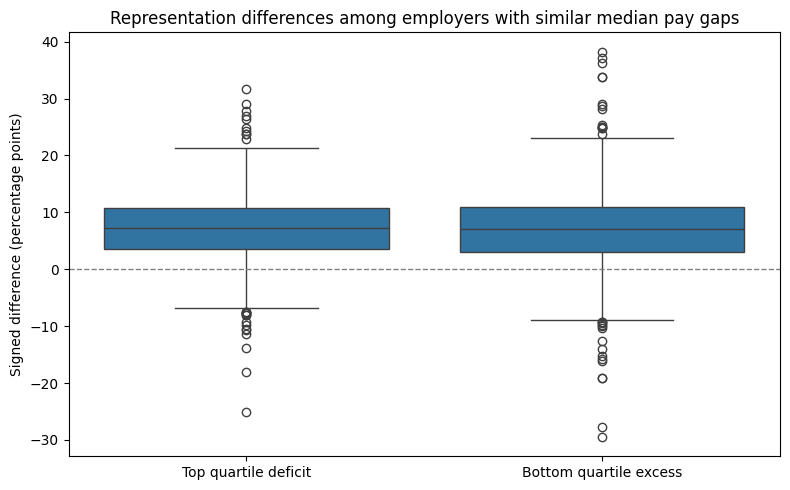

In [5]:
# Josh — Section 5: visual analysis (AI-assisted: OpenAI GPT-6, November 2026)
# Verify and disclose under BA305 project §9.
plot_long = usable[['TopDeficit_pp','BottomExcess_pp']].rename(columns={
    'TopDeficit_pp': 'Top quartile deficit',
    'BottomExcess_pp': 'Bottom quartile excess'
}).melt(var_name='Measure', value_name='Percentage points')

plt.figure(figsize=(8,5))
sns.boxplot(data=plot_long, x='Measure', y='Percentage points')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Representation differences among employers with similar median pay gaps')
plt.xlabel('')
plt.ylabel('Signed difference (percentage points)')
plt.tight_layout()
plt.show()

## 6. Scatterplot: one point for each employer

In this chart, **each dot represents one employer** in my filtered sample.

- **Left to right:** the top deficit.
- **Bottom to top:** the bottom excess.
- **Below the dashed diagonal line:** the top-deficit number is larger.
- **Above the diagonal:** the bottom-excess number is larger.
- **Close to the diagonal:** the two measurements are similar.

If a dot is outside the area where **both values are positive**, I need to be careful about using words like 'deficit' or 'excess' for that company.

**What I want to see:** Are employers spread across both sides of the diagonal? Are there different kinds of representation patterns even when their pay gaps are similar?

This is an association in the data, not evidence of what caused the pay gap.


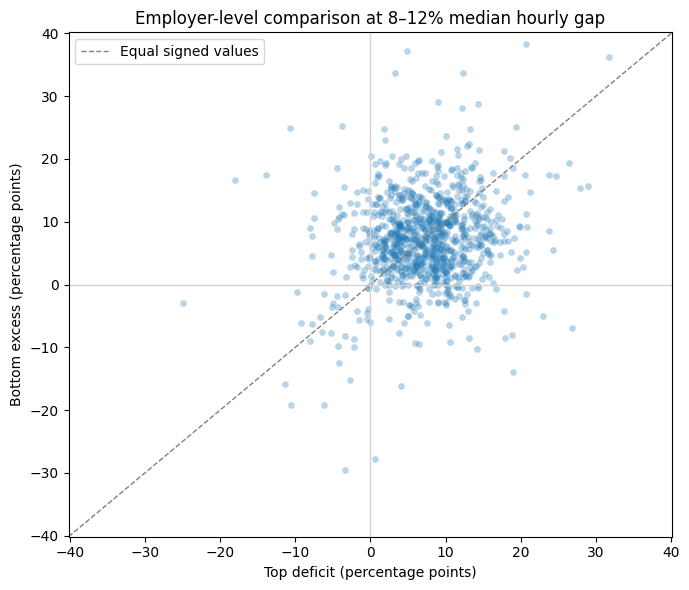

In [6]:
# Josh — Section 6: visual analysis (AI-assisted: OpenAI GPT-6, November 2026)
# Verify and disclose under BA305 project §9.
fig, ax = plt.subplots(figsize=(7,6))
sns.scatterplot(data=usable, x='TopDeficit_pp', y='BottomExcess_pp',
                alpha=0.3, s=24, linewidth=0, ax=ax)
x = usable['TopDeficit_pp']; y = usable['BottomExcess_pp']
lim = max(5.0, float(np.nanmax(np.abs(np.r_[x.values, y.values])))*1.05)
ax.plot([-lim,lim], [-lim,lim], linestyle='--', color='gray', linewidth=1, label='Equal signed values')
ax.axhline(0, color='lightgray', linewidth=1)
ax.axvline(0, color='lightgray', linewidth=1)
ax.set(xlim=(-lim,lim),ylim=(-lim,lim),
       xlabel='Top deficit (percentage points)',
       ylabel='Bottom excess (percentage points)',
       title='Employer-level comparison at 8–12% median hourly gap')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Count how common each pattern is

The scatterplot shows individual employers, but I also want a simple count of the different patterns.

I'm putting employers into four **descriptive groups**:

- **Top deficit larger:** the positive top deficit is more than **2 percentage points** larger than bottom excess.
- **Bottom excess larger:** the positive bottom excess is more than **2 points** larger than top deficit.
- **Similar/unclear:** the difference is too small to clearly favor either one under this rule.
- **Neither positive:** neither of those two patterns is positive.

The **2-point cutoff** is just a working choice to avoid treating tiny differences as important. It isn't a law or a proven fairness threshold. I'll test other cutoffs later.

**What I want to know:** Is one pattern much more common, or do both show up a lot? If both are common, that is still a useful result.

These labels describe **where women are represented**, not what caused the pay gap or whether the employer qualifies for certification.


,Employers,Percent of sample
Pattern,,
Top deficit larger,376,38.3
Bottom excess larger,375,38.2
Similar/unclear,198,20.2
Neither positive,33,3.4


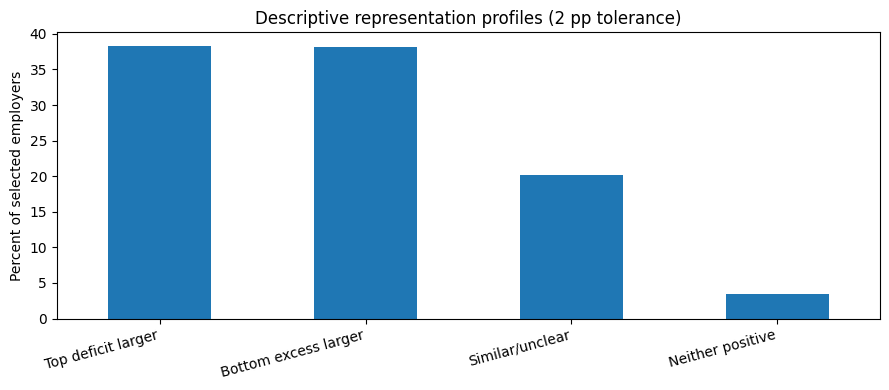

Interpretation prompt: Are both profiles present? Does one actually dominate?


In [7]:
# Josh — Section 7: descriptive pattern labels (AI-assisted: OpenAI GPT-6, November 2026)
def pattern_label(top, bottom, tolerance=2):
    if top <= 0 and bottom <= 0:
        return 'Neither positive'
    if top > 0 and (top - bottom) > tolerance:
        return 'Top deficit larger'
    if bottom > 0 and (bottom - top) > tolerance:
        return 'Bottom excess larger'
    return 'Similar/unclear'

TOLERANCE_PP = 2
pattern_order = ['Top deficit larger', 'Bottom excess larger',
                 'Similar/unclear', 'Neither positive']
usable['Pattern'] = [pattern_label(t,b,TOLERANCE_PP) for t,b in
                     zip(usable['TopDeficit_pp'], usable['BottomExcess_pp'])]
counts = usable['Pattern'].value_counts().reindex(pattern_order, fill_value=0)
pattern_table = pd.DataFrame({
    'Employers': counts,
    'Percent of sample': (100 * counts / len(usable)).round(1)
})
display(pattern_table)
ax = pattern_table['Percent of sample'].plot(kind='bar', figsize=(9,4))
ax.set(xlabel='',ylabel='Percent of selected employers',
       title='Descriptive representation profiles (2 pp tolerance)')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()
print('Interpretation prompt: Are both profiles present? Does one actually dominate?')


## 8. Compare two real employers with similar gaps

This is where I can make the analysis easier to understand. Instead of only showing a chart with lots of dots, I'll compare **two actual employers** with similar median hourly pay gaps but different top/bottom patterns.

**How I'll choose the pair:**
1. First, try two employers in the **same industry and size group**, with reported gaps within **0.5 percentage points**.
2. If that isn't possible, try the **same size group** and similarly close gaps.
3. If that still isn't possible, look for close gaps across the full sample.
4. If none meet the 0.5-point rule, use the closest available pair and **say that the match is weaker**.

The code only compares employers that fall into opposite descriptive groups. It does not make up a pair when none exists. It also prints which matching rule worked.

**What I'm looking for:** How can the two employers have similar pay-gap numbers but different percentages of women in the four quartiles?

**Why the organization would care:** The next questions might be different for each employer. For example, it may want more detail on senior jobs and promotions for one employer, or on lower-paid roles and career progression for another. Those are **questions to investigate**, not proven explanations.

**Limit:** Two employers help tell the story, but they do not represent every employer in the dataset.


Matching rule used: same industry AND employer-size band; gaps within 0.5 pp
Difference between reported median hourly gaps (pp): 0.0
These are examples of workforce composition, NOT evidence of cause.


,EmployerName,EmployerId,EmployerSize,Industry,DiffMedianHourlyPercent,FemaleLowerQuartile,FemaleLowerMiddleQuartile,FemaleUpperMiddleQuartile,FemaleTopQuartile,OverallFemaleShareApprox,TopDeficit_pp,BottomExcess_pp,Contrast_pp
Example,,,,,,,,,,,,,
Employer A: top deficit larger,MCPHILLIPS (WELLINGTON) LIMITED,8264,250 to 499,Manufacturing,9.8,2.8,10.1,1.5,1.5,3.97,2.47,-1.17,3.65
Employer B: bottom excess larger,DORMAKABA UK LIMITED,4210,250 to 499,Manufacturing,9.8,40.8,21.2,19.2,21.2,25.60,4.40,15.20,-10.80


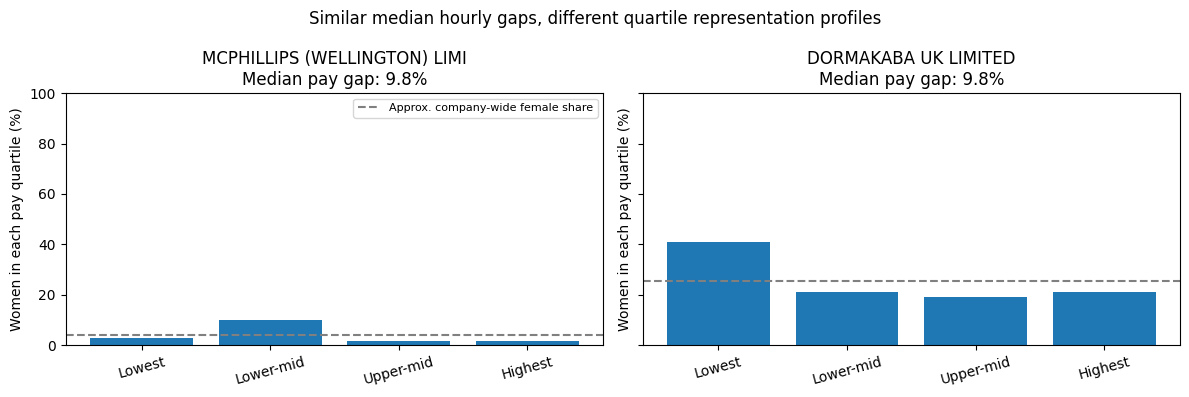

In [8]:
# Josh — Section 8: matched employer example (AI-assisted: OpenAI GPT-6, November 2026)
top_cases = usable.loc[usable['Pattern'] == 'Top deficit larger'].copy()
bottom_cases = usable.loc[usable['Pattern'] == 'Bottom excess larger'].copy()

pair = None
chosen_rule = None
if top_cases.empty or bottom_cases.empty:
    print('Cannot create opposite-profile pair: at least one profile has no employers.')
else:
    # Attempt more comparable pairs first; fall back transparently.
    matching_rules = [
        ('same industry AND employer-size band; gaps within 0.5 pp', ['Industry','EmployerSize'], 0.5),
        ('same employer-size band; gaps within 0.5 pp', ['EmployerSize'], 0.5),
        ('gaps within 0.5 pp; industry/size may differ', [], 0.5),
        ('closest pair in the 8–12% band; potentially looser match', [], None),
    ]
    for rule_name, keys, max_gap_distance in matching_rules:
        if keys:
            candidate_pairs = top_cases.merge(bottom_cases, on=keys, suffixes=('_top','_bottom'))
        else:
            candidate_pairs = top_cases.assign(_join=1).merge(
                bottom_cases.assign(_join=1), on='_join', suffixes=('_top','_bottom'))
            candidate_pairs = candidate_pairs.drop(columns='_join')
        if candidate_pairs.empty:
            continue
        candidate_pairs = candidate_pairs.loc[
            candidate_pairs['EmployerId_top'] != candidate_pairs['EmployerId_bottom']
        ].copy()
        candidate_pairs['GapDistance_pp'] = (
            candidate_pairs['DiffMedianHourlyPercent_top'] - candidate_pairs['DiffMedianHourlyPercent_bottom']
        ).abs()
        if max_gap_distance is not None:
            candidate_pairs = candidate_pairs.loc[
                candidate_pairs['GapDistance_pp'] <= max_gap_distance
            ].copy()
        if candidate_pairs.empty:
            continue
        candidate_pairs['ContrastDifference_pp'] = (
            candidate_pairs['Contrast_pp_top'] - candidate_pairs['Contrast_pp_bottom']
        ).abs()
        typical_difference = candidate_pairs['ContrastDifference_pp'].median()
        candidate_pairs['DistanceFromTypical'] = (
            candidate_pairs['ContrastDifference_pp'] - typical_difference
        ).abs()
        # Closest gaps first; within a tie, favor typical rather than extreme contrast.
        pair = candidate_pairs.sort_values(
            ['GapDistance_pp','DistanceFromTypical'], ascending=[True,True]
        ).iloc[0]
        chosen_rule = rule_name
        break

if pair is not None:
    print('Matching rule used:', chosen_rule)
    print('Difference between reported median hourly gaps (pp):',
          round(float(pair['GapDistance_pp']), 2))
    print('These are examples of workforce composition, NOT evidence of cause.')
    compare_rows=[]
    for label, suf in [('Employer A: top deficit larger', '_top'),
                       ('Employer B: bottom excess larger', '_bottom')]:
        # Merge keys appear without suffixes when matched; retrieve those accordingly.
        row={'Example': label}
        for col in ['EmployerName','EmployerId','EmployerSize','Industry',
                    'DiffMedianHourlyPercent'] + female_cols + [
                    'OverallFemaleShareApprox','TopDeficit_pp','BottomExcess_pp','Contrast_pp']:
            key = col + suf if col + suf in pair.index else col
            row[col] = pair[key]
        compare_rows.append(row)
    matched_examples = pd.DataFrame(compare_rows)
    display(matched_examples.set_index('Example').round(2))

    fig, axes = plt.subplots(1,2,figsize=(12,4),sharey=True)
    for ax, (_, ex) in zip(axes, matched_examples.iterrows()):
        ax.bar(['Lowest','Lower-mid','Upper-mid','Highest'], [ex[c] for c in female_cols])
        ax.axhline(ex['OverallFemaleShareApprox'], color='gray', linestyle='--',
                   label='Approx. company-wide female share')
        ax.set_ylim(0,100)
        ax.set_title(f"{str(ex['EmployerName'])[:28]}\nMedian pay gap: {ex['DiffMedianHourlyPercent']:.1f}%")
        ax.set_ylabel('Women in each pay quartile (%)')
        ax.tick_params(axis='x', rotation=15)
    axes[0].legend(fontsize=8)
    fig.suptitle('Similar median hourly gaps, different quartile representation profiles')
    plt.tight_layout()
    plt.show()
else:
    print('No valid pair from opposite labels. Report this and examine the sample size.')


## 9. Check whether employer size changes the picture

I don't want to assume the overall result looks the same for every size of company. So I'll separate employers by their size groups and look at the **spread** of the contrast in each group.

**What I'll check:** Do the boxplots look different? Do they overlap a lot? Are some groups too small to say much about?

**Why it matters:** If the pattern looks different across size groups, the certification organization might need to take employer size into account when deciding what to review.

Remember, `Contrast_pp` compares two representation measurements. **It is not a discrimination score or a certification grade.**


Sample sizes by employer-size category:


,Employers
EmployerSize,
250 to 499,410
500 to 999,239
1000 to 4999,242
"5000 to 19,999",80
"20,000 or more",11


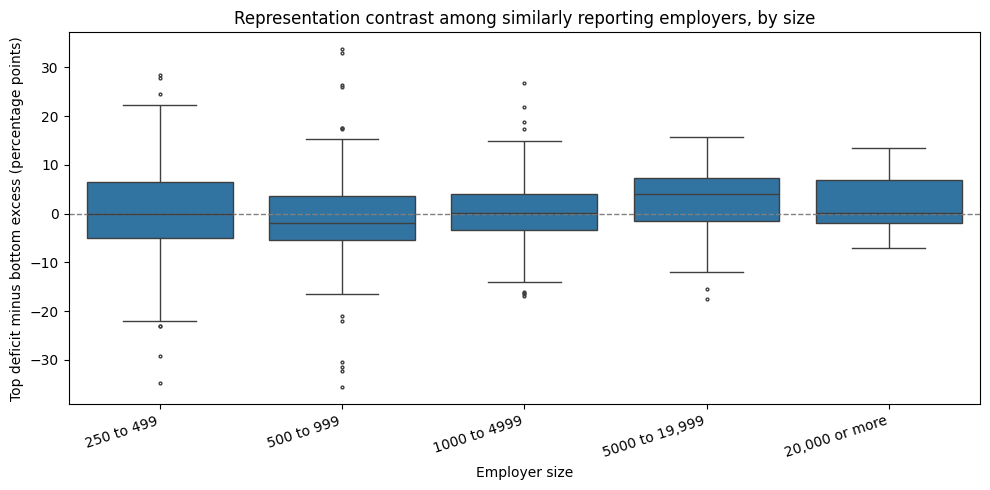

In [9]:
# Josh — Section 9: employer size as a third variable (AI-assisted: OpenAI GPT-6, November 2026)
size_counts = usable['EmployerSize'].value_counts().reindex(size_order,fill_value=0)
print('Sample sizes by employer-size category:')
display(size_counts.to_frame('Employers'))
plt.figure(figsize=(10,5))
sns.boxplot(data=usable, x='EmployerSize', y='Contrast_pp',
            order=[s for s in size_order if size_counts[s]>0], fliersize=2)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.xticks(rotation=18, ha='right')
plt.xlabel('Employer size')
plt.ylabel('Top deficit minus bottom excess (percentage points)')
plt.title('Representation contrast among similarly reporting employers, by size')
plt.tight_layout()
plt.show()


## 10. Check whether industry changes the picture

Next I'll ask the same question for **industry**. Even among employers with an **8%–12% median hourly gap**, do some industries show different top-versus-bottom representation patterns?

To keep the graph readable, the code will show up to **six industries** that each have at least **30 employers in this filtered sample**. That's a charting choice, not an official statistical cutoff.

**What I'll check:** The medians, the spread, whether groups overlap, and how many employers are in each industry.

**Why I'm doing this:** Industry could be one reason the overall picture looks different when employers are separated into groups. I still cannot say industry *caused* the pay gap. And I'm not trying to rank industries by the size of their pay gaps; I'm staying with my representation question.


Industries plotted and employer counts:


,Employers
Industry,
Manufacturing,208
Education,99
Wholesale & Retail Trade,90
Health/SocialWork,83
Unknown,81
Scientific/Technical,76


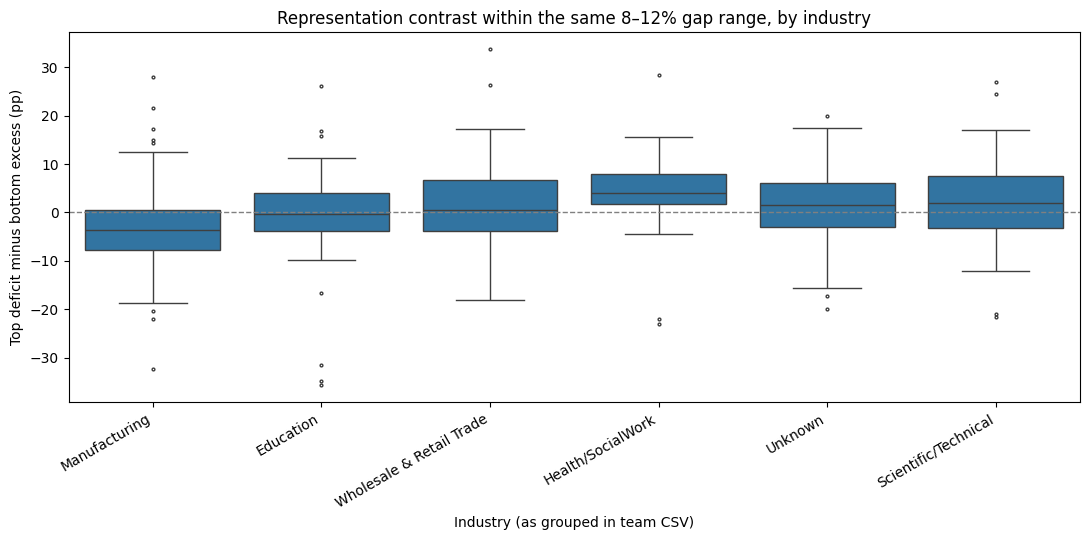

In [10]:
# Josh — Section 10: industry as a third variable (AI-assisted: OpenAI GPT-6, November 2026)
usable['Industry'] = usable['Industry'].fillna('Unknown').astype(str)
industry_counts = usable['Industry'].value_counts()
plot_industries = industry_counts[industry_counts>=30].head(6).index.tolist()
print('Industries plotted and employer counts:')
display(industry_counts.reindex(plot_industries).to_frame('Employers'))
if plot_industries:
    sub = usable.loc[usable['Industry'].isin(plot_industries)].copy()
    plt.figure(figsize=(11,5.5))
    sns.boxplot(data=sub, x='Industry', y='Contrast_pp',
                order=plot_industries, fliersize=2)
    plt.axhline(0, color='gray', linestyle='--', linewidth=1)
    plt.xticks(rotation=30, ha='right')
    plt.xlabel('Industry (as grouped in team CSV)')
    plt.ylabel('Top deficit minus bottom excess (pp)')
    plt.title('Representation contrast within the same 8–12% gap range, by industry')
    plt.tight_layout()
    plt.show()
else:
    print('No industry has at least 30 eligible employers; this chart is omitted.')


## 11. Check whether my choices change the answer

I chose the **8%–12% gap range** and the **2-percentage-point cutoff** myself. Before trusting the result, I need to see if a slightly different choice changes the story.

The code checks:

- **Gap ranges:** 5%–15%, 8%–12%, and 9%–11%.
- **Pattern cutoffs:** 0, 1, 2, and 5 percentage points.

It uses the **same cleaning steps** for every comparison.

**What I want to know:** Do the main patterns still show up when I change these choices? If the conclusion flips, I need to say that instead of picking only the version that looks best.

**Why this matters:** A certification organization should not make decisions based on a pattern that only appears because I picked one particular cutoff.


In [11]:
# Josh — Section 11: sensitivity checks (AI-assisted: OpenAI GPT-6, November 2026)
def check_rules(low, high, tolerance):
    group, audit_row = prepare_sample(low, high)
    row = {'Gap range': f'{low}–{high}%',
           'Tolerance (pp)': tolerance,
           'Employer rows': len(group),
           'Excluded after filter': audit_row['gap/size filter n'] - len(group)}
    if group.empty:
        for label in pattern_order:
            row[label+' (%)'] = np.nan
        return row
    overall = group[female_cols].mean(axis=1)
    top = overall - group['FemaleTopQuartile']
    bottom = group['FemaleLowerQuartile'] - overall
    labels = pd.Series([pattern_label(t,b,tolerance) for t,b in zip(top,bottom)])
    for label in pattern_order:
        row[label+' (%)'] = round(100*(labels==label).mean(),1)
    return row

robustness = pd.DataFrame([
    check_rules(lo,hi,tol)
    for lo,hi in [(5,15),(8,12),(9,11)]
    for tol in [0,1,2,5]
])
display(robustness)
print('Question: Do the same profiles remain common when our arbitrary bands change?')


,Gap range,Tolerance (pp),Employer rows,Excluded after filter,Top deficit larger (%),Bottom excess larger (%),Similar/unclear (%),Neither positive (%)
0,5–15%,0,2401,34,48.6,46.5,1.3,3.5
1,5–15%,1,2401,34,43.6,41.6,11.3,3.5
2,5–15%,2,2401,34,39.7,36.1,20.7,3.5
3,5–15%,5,2401,34,25.7,22.4,48.3,3.5
4,8–12%,0,982,15,47.4,47.7,1.6,3.4
5,8–12%,1,982,15,42.5,43.6,10.6,3.4
6,8–12%,2,982,15,38.3,38.2,20.2,3.4
7,8–12%,5,982,15,25.3,22.9,48.5,3.4
8,9–11%,0,505,5,46.9,47.9,1.8,3.4
9,9–11%,1,505,5,42.6,44.2,9.9,3.4


Question: Do the same profiles remain common when our arbitrary bands change?


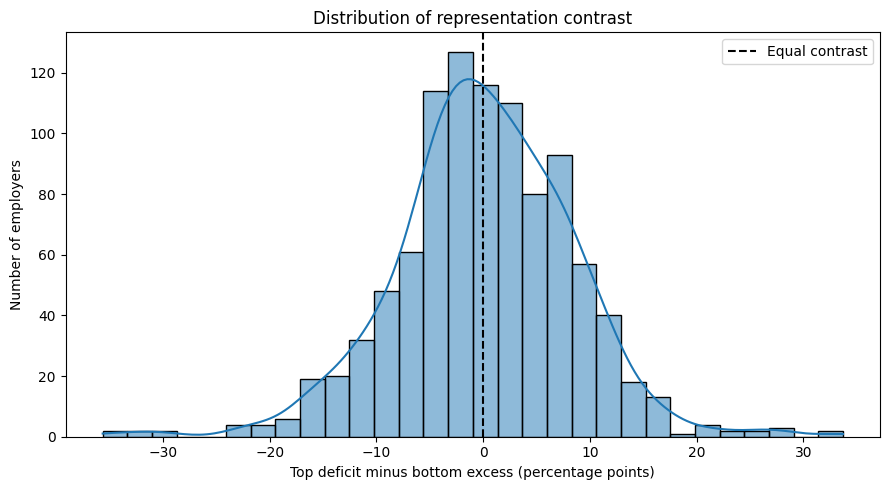

count    982.00
mean       0.09
std        8.35
min      -35.65
25%       -4.75
50%        0.00
75%        5.50
max       33.70
Name: Contrast_pp, dtype: float64


In [12]:

# Josh — Additional descriptive check
# AI-assisted code: OpenAI GPT-6; disclose under project requirements.

plt.figure(figsize=(9, 5))

sns.histplot(
    data=usable,
    x='Contrast_pp',
    bins=30,
    kde=True
)

plt.axvline(0, color='black', linestyle='--', label='Equal contrast')
plt.xlabel('Top deficit minus bottom excess (percentage points)')
plt.ylabel('Number of employers')
plt.title('Distribution of representation contrast')
plt.legend()
plt.tight_layout()
plt.show()

print(usable['Contrast_pp'].describe().round(2))


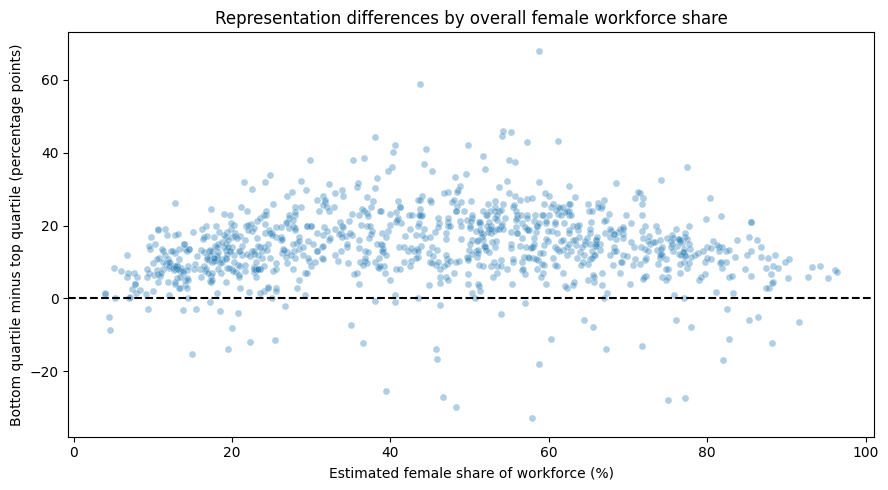

In [13]:

# Josh — Workforce composition as a third variable
# AI-assisted code: OpenAI GPT-6; disclose under project requirements.

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=usable,
    x='OverallFemaleShareApprox',
    y='BottomMinusTop_pp',
    alpha=0.35,
    s=25
)

plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Estimated female share of workforce (%)')
plt.ylabel('Bottom quartile minus top quartile (percentage points)')
plt.title('Representation differences by overall female workforce share')
plt.tight_layout()
plt.show()


Representation differences by workforce composition:


,Employers,Median_pp,Mean_pp,Q1_pp,Q3_pp
FemaleShareGroup,,,,,
0–25%,255,10.6,10.60,6.9,14.75
25–50%,285,17.0,16.94,11.0,23.30
50–75%,337,16.4,16.42,11.2,22.00
75–100%,105,11.4,9.80,6.6,14.40


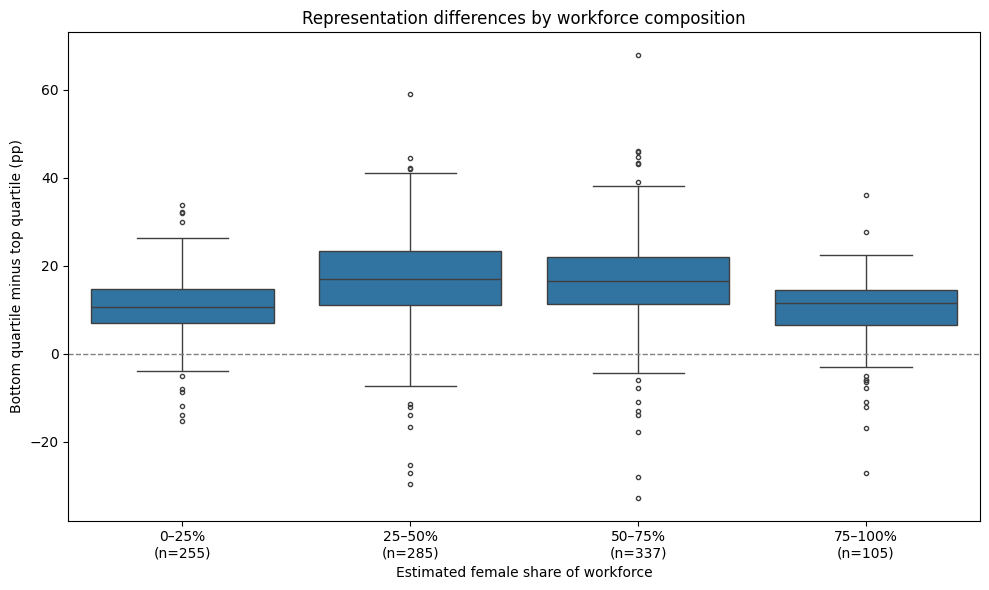

In [14]:

# Josh — Additional descriptive analysis
# AI-assisted code: OpenAI GPT-6, November 2026
# Check female workforce share as a third variable.

# Step 1: Create four groups based on the estimated
# percentage of women in each employer's workforce.

plot_df = usable.copy()

group_labels = [
    '0–25%',
    '25–50%',
    '50–75%',
    '75–100%'
]

plot_df['FemaleShareGroup'] = pd.cut(
    plot_df['OverallFemaleShareApprox'],
    bins=[0, 25, 50, 75, 100],
    labels=group_labels,
    include_lowest=True
)

# Step 2: Summarize the differences within each group.

group_summary = (
    plot_df.groupby('FemaleShareGroup', observed=False)
    ['BottomMinusTop_pp']
    .agg(
        Employers='count',
        Median_pp='median',
        Mean_pp='mean',
        Q1_pp=lambda x: x.quantile(0.25),
        Q3_pp=lambda x: x.quantile(0.75)
    )
)

print('Representation differences by workforce composition:')
display(group_summary.round(2))

# Step 3: Create boxplots to show the distribution
# within each group, not just the average.

plt.figure(figsize=(10, 6))

ax = sns.boxplot(
    data=plot_df,
    x='FemaleShareGroup',
    y='BottomMinusTop_pp',
    order=group_labels,
    fliersize=3
)

plt.axhline(
    0,
    color='gray',
    linestyle='--',
    linewidth=1
)

# Show the number of employers in each group.
counts = (
    plot_df['FemaleShareGroup']
    .value_counts()
    .reindex(group_labels, fill_value=0)
)

ax.set_xticks(range(len(group_labels)))
ax.set_xticklabels([
    f'{label}\n(n={counts[label]})'
    for label in group_labels
])

plt.xlabel('Estimated female share of workforce')
plt.ylabel('Bottom quartile minus top quartile (pp)')
plt.title(
    'Representation differences by workforce composition'
)

plt.tight_layout()
plt.show()
